# 01. Regresión con Redes Neuronales en TensorFlow

Existen muchas definiciones para un [problema de regresión](https://es.wikipedia.org/wiki/An%C3%A1lisis_de_regresi%C3%B3n), pero en nuestro caso, vamos a simplificarlo a **predecir un número**.

Por ejemplo, podrías querer:
- Predecir el precio de venta de casas dada información sobre ellas (como el número de habitaciones, tamaño, número de baños).
- Predecir las coordenadas de un cuadro delimitador de un objeto en una imagen.
- Predecir el coste de un seguro médico para una persona dada su demografía (edad, sexo, género, raza).

En este notebook, vamos a establecer las bases de cómo tomar una muestra de entradas (estos son tus datos), construir una red neuronal para descubrir patrones en esas entradas y luego hacer una predicción (en forma de un número) basada en esas entradas.

## Lo que vamos a cubrir

Específicamente, vamos a hacer las siguientes tareas con TensorFlow:
- Arquitectura de un modelo de regresión
- Formas de las entradas y salidas
  - `X`: características/datos (entradas)
  - `y`: etiquetas (salidas)
- Crear datos personalizados para visualizar y ajustar
- Pasos en el modelado
  - Crear un modelo
  - Compilar un modelo
    - Definir una función de pérdida
    - Configurar un optimizador
    - Crear métricas de evaluación
  - Ajustar un modelo (hacer que encuentre patrones en nuestros datos)
- Evaluar un modelo
  - Visualizar el modelo
  - Observar las curvas de entrenamiento
  - Comparar las predicciones con los valores reales (usando nuestras métricas de evaluación)
- Guardar un modelo (para poder usarlo más tarde)
- Cargar un modelo

## Arquitectura típica de una red neuronal de regresión


| **Hiperparámetro** | **Valor típico** |
| --- | --- |
| Forma de la capa de entrada | Igual a la cantidad de características (por ejemplo, 3 para # habitaciones, # baños, # espacios para autos en la predicción de precio de casas) |
| Capa(s) oculta(s) | Específico del problema, mínimo = 1, máximo = ilimitado |
| Neuronas por capa oculta | Específico del problema, generalmente de 10 a 100 |
| Forma de la capa de salida | Igual a la forma de la predicción deseada (por ejemplo, 1 para el precio de una casa) |
| Activación en las capas ocultas | Generalmente [ReLU](https://www.kaggle.com/dansbecker/rectified-linear-units-relu-in-deep-learning) (unidad lineal rectificada) |
| Activación en la salida | Ninguna, ReLU, logística/tanh |
| Función de pérdida | [MSE](https://es.wikipedia.org/wiki/Error_cuadr%C3%A1tico_medio) (error cuadrático medio) o [MAE](https://es.wikipedia.org/wiki/Error_absoluto_medio) (error absoluto medio)/Huber (combinación de MAE/MSE) si hay valores atípicos |
| Optimizador | [SGD](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/SGD) (descenso de gradiente estocástico), [Adam](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam) |

*Tabla 1: Arquitectura típica de una red de regresión. Fuente: Adaptado de la página 293 del [libro Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow de Aurélien Géron](https://www.oreilly.com/library/view/hands-on-machine-learning/9781492032632/)*

> 🔑 **Nota:** Un **hiperparámetro** en el aprendizaje automático es algo que un analista de datos o desarrollador puede configurar por sí mismo, mientras que un **parámetro** generalmente describe algo que un modelo aprende por sí mismo (un valor que no es configurado explícitamente por un analista).


In [2]:
# primero, vamos a importar librerías
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from keras.src.utils.jax_layer_test import input_shape

print(tf.__version__) # check the version (should be 2.x+)

import datetime
print(f"Última ejecución del notebook: {datetime.datetime.now()}")

2.21.0
Última ejecución del notebook: 2026-11-09 16:27:48.657365


## Crear datos para visualizarlos y entrenar

Como estamos trabajando en un problema de **regresión** (predecir un número) vamos a crear algunos datos lineales para modelarlos


## Formas de entrada y salida en regresión

Uno de los conceptos más importantes al trabajar con redes neuronales son las formas de entrada y salida.

La **forma de entrada** (input shape) es la forma de tus datos que ingresan al modelo.

La **forma de salida** (output shape) es la forma de los datos que quieres que salgan de tu modelo.

Estas **formas** (shapes) variarán dependiendo del problema en el que estés trabajando.

Las redes neuronales aceptan números y generan números. Estos números generalmente se representan como tensores (o arrays).

![ejemplo de formas de entrada y salida](https://fp.cloud.riberadeltajo.es/imagenes_cursos/regresionCasas.png)


In [4]:
# Ejemplo de formas de entrada y salida
info_casas = tf.constant([[0,1,0,0], [0,0,0,1], [0,1,0,0]])
precio_casa = tf.constant([249990])


# visualiza los dos tensores, ¿Qué forma tienen?
print(info_casas.shape)
print(precio_casa.shape)

(3, 4)
(1,)


#### generamos datos para visualizar

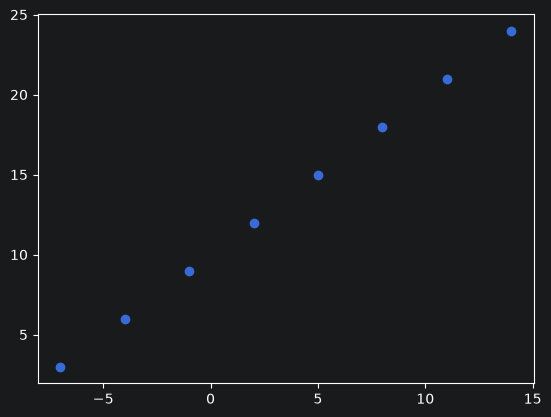

In [5]:
# Crea un tensor X de características con valores [-7.0, -4.0, -1.0, 2.0, 5.0, 8.0, 11.0, 14.0]
X = tf.constant(np.array([-7.0, -4.0, -1.0, 2.0, 5.0, 8.0, 11.0, 14.0]))
# Crea un tensor y de características con valores [3.0, 6.0, 9.0, 12.0, 15.0, 18.0, 21.0, 24.0]
y = tf.constant(np.array([3.0, 6.0, 9.0, 12.0, 15.0, 18.0, 21.0, 24.0]))
# Visualízalo con matplotlib
plt.scatter(X, y)
plt.show()

Nuestro objetivo aquí será usar `X` para predecir `y`.

Entonces, nuestra **entrada** será `X` y nuestra **salida** será `y`.

Sabiendo esto, ¿qué crees que serán nuestras formas de entrada y salida?

Vamos a explorar estas variables.


In [7]:
# Coge una muestra del tensor X y otra del tensor y
input_shape = X[0].shape
output_shape = y[1].shape

# ¿Qué forma tienen?
input_shape, output_shape

(TensorShape([]), TensorShape([]))

los dos resultados son tensores de rango 0 o escalares 

## Pasos para modelar con TensorFlow

Ahora que sabemos qué datos tenemos, así como las formas de entrada y salida, veamos cómo construiríamos una red neuronal para modelarlos.

En TensorFlow, generalmente hay 3 pasos fundamentales para crear y entrenar un modelo.

1. **Crear un modelo** - ensamblar las capas de una red neuronal tu mismo (usando la [API Funcional](https://www.tensorflow.org/guide/keras/functional) o la [API Secuencial](https://www.tensorflow.org/api_docs/python/tf/keras/Sequential)) o importar un modelo previamente construido (conocido como aprendizaje por transferencia).
2. **Compilar un modelo** - definir cómo debe medirse el rendimiento de un modelo (pérdida/métricas) y también cómo debe mejorar (optimizador).
3. **Ajustar un modelo** - permitir que el modelo intente encontrar patrones en los datos (¿cómo se relaciona `X` con `y`?).

Veamos estos pasos en acción usando la [API Secuencial de Keras](https://www.tensorflow.org/api_docs/python/tf/keras/Sequential) para construir un modelo para nuestros datos de regresión. Luego repasaremos cada uno de ellos.


In [10]:
tf.expand_dims(X, axis=-1).shape

TensorShape([8, 1])

In [24]:
# a partir de esta semilla:
tf.random.set_seed(42)

# crea un modelo sequencial con una capa densa de tan sólo una unidad

model = tf.keras.Sequential([
  tf.keras.layers.Dense(1),
  tf.keras.layers.Dense(40),
  tf.keras.layers.Dense(1)
])

# compila el modelo
# utilizando como función de pérdida y métrica "mae - mean absolute error", como optimizador "stochastic gradient descent"
# loss=, metrics=, optimizer=
model.compile(optimizer='sgd', loss='mae', metrics=['mae'])
              
# entrena el modelo utilizando la función fit durante 5 épocas
model.fit(tf.expand_dims(X, axis=-1), y, epochs=200)

Epoch 1/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - loss: 13.4358 - mae: 13.4358
Epoch 2/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 13.3985 - mae: 13.3985
Epoch 3/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 13.3597 - mae: 13.3597
Epoch 4/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 13.3192 - mae: 13.3192
Epoch 5/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 13.2767 - mae: 13.2767
Epoch 6/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 13.2319 - mae: 13.2319
Epoch 7/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 13.1845 - mae: 13.1845
Epoch 8/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 13.1340 - mae: 13.1340
Epoch 9/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 13.0799 - mae: 13.0799
Epoch 10/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 13.0217 - mae: 13.0217
Epoch 11/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 12.9587 - mae: 12.9587
Epoch 12/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 12.8903 - mae: 12.8903
Epoch 13/200
1/1 ━━━━━━━

Ya hemos entrenado nuestro modelo, ¿cómo crees que ha ido?

In [30]:
# Haz una predicción para el número 17
model.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


array([[ 5.303729],
       [ 7.044245],
       [ 8.784761],
       [10.525275],
       [12.265794],
       [14.006309],
       [15.746825],
       [17.48734 ]], dtype=float32)

Parece ser que no ha predicho demasiado bien, la salida debería haber sido cerca de 27

## Mejorando un modelo


Para mejorar nuestro modelo, podemos modificar casi todas las partes de los 3 pasos que tenemos para crear el modelo:

1. **Crear un modelo** - aquí podrías querer agregar más capas, aumentar el número de neuronas (unidades ocultas) dentro de cada capa, o cambiar las funciones de activación de cada capa.
2. **Compilar un modelo** - podrías elegir otra función de optimización o quizás cambiar la **tasa de aprendizaje** de la función de optimización.
3. **Ajustar un modelo** - podrías entrenar el modelo más **épocas** o usar más datos (darle más ejemplos al modelo para que aprenda).

![formas diferentes de mejorar un modelo de red neuronal](https://fp.cloud.riberadeltajo.es/imagenes_cursos/MejorarModelo.png)

*Existen muchas formas diferentes de mejorar potencialmente una red neuronal. Algunas de las más comunes incluyen: aumentar el número de capas (haciendo la red más profunda), aumentar el número de unidades ocultas (haciendo la red más ancha) y cambiar la tasa de aprendizaje. Como estos valores son modificables por el humano, se les llama [hiperparámetros](https://es.wikipedia.org/wiki/Hiperpar%C3%A1metro_(aprendizaje_autom%C3%A1tico)) y la práctica de tratar de encontrar los mejores hiperparámetros se conoce como [ajuste de hiperparámetros](https://es.wikipedia.org/wiki/Optimización_de_hiperparámetros).*



## Formas comunes de mejorar un modelo:

- **Añadir capas**
- **Incrementar el número de unidades ocultas**
- **Cambiar las funciones de activación**
- **Cambiar la función de optimización**
- **Cambiar la tasa de aprendizaje** (porque puedes alterar cada una de las capas, son hiperparámetros)
- **Entrenar con más datos**
- **Entrenar por más tiempo** (más épocas)


### Ahora tu: Intenta entrenar más épocas
Nuestro primer instinto es entrenar por más tiempo. ¿Da siempre esto el resultado esperado?

In [ ]:
# reproduce el modelo anterior y entrena con 100 épocas

Habrás notado que el valor de la pérdida ha disminuido (y sigue disminuyendo a medida que aumenta el número de épocas).

¿Podremos hacer una predicción fiable con nuestro modelo?

¿Qué tal si intentamos predecir nuevamente con 17.0?


In [ ]:
# Predice de nuevo la salida de la entrada 17. ¿Ha mejorado?

Mucho mejor! Estamos más cerca, pero no lo suficiente...
¿o sí?

¿cómo lo evaluamos?

## Evaluando un modelo

Un flujo de trabajo típico que seguirás al construir redes neuronales es:

Construir un modelo -> evaluarlo -> construir (ajustar) un modelo -> evaluarlo -> construir (ajustar) un modelo -> evaluarlo...


Los ajustes vienen de no construir un modelo desde cero, sino de modificar uno existente.

### Visualizar

Probablemente aprenderás más observando algo (haciendo) que pensando en algo.

Es una buena idea visualizar:
* **Los datos** - ¿con qué datos estás trabajando? ¿Cómo se ven?
* **El propio modelo** - ¿cómo se ve la arquitectura? ¿Cuáles son las diferentes formas?
* **El entrenamiento de un modelo** - ¿cómo rinde un modelo mientras aprende?
* **Las predicciones de un modelo** - ¿cómo se alinean las predicciones de un modelo con la verdad real (las etiquetas originales)?

Empecemos visualizando el modelo.

Pero primero, crearemos un conjunto de datos un poco más grande y un nuevo modelo que podamos usar (será el mismo que antes, pero más práctica siempre es mejor).


In [31]:
# crea un array X en numpy con el método arange para generar números  desde -100 a 100, de 4 en 4
X = np.arange(-100,100,4)
X

array([-100,  -96,  -92,  -88,  -84,  -80,  -76,  -72,  -68,  -64,  -60,
        -56,  -52,  -48,  -44,  -40,  -36,  -32,  -28,  -24,  -20,  -16,
        -12,   -8,   -4,    0,    4,    8,   12,   16,   20,   24,   28,
         32,   36,   40,   44,   48,   52,   56,   60,   64,   68,   72,
         76,   80,   84,   88,   92,   96])

In [32]:
# creamos datos para las etiquetas (X+10)
y = X+10
y

array([-90, -86, -82, -78, -74, -70, -66, -62, -58, -54, -50, -46, -42,
       -38, -34, -30, -26, -22, -18, -14, -10,  -6,  -2,   2,   6,  10,
        14,  18,  22,  26,  30,  34,  38,  42,  46,  50,  54,  58,  62,
        66,  70,  74,  78,  82,  86,  90,  94,  98, 102, 106])

## Dividir los datos en conjunto de entrenamiento/prueba

Uno de los pasos más comunes e importantes en un proyecto de aprendizaje automático es la creación de un conjunto de entrenamiento y un conjunto de prueba (y cuando es necesario, un conjunto de validación).

Cada conjunto tiene un propósito específico:
* **Conjunto de entrenamiento** _training_: el modelo aprende de estos datos, que suelen representar el 70-80% del total de datos disponibles (como los materiales de estudio que repasas durante el semestre).
* **Conjunto de validación** _validation_: el modelo se ajusta con estos datos, que suelen representar el 10-15% del total de datos disponibles (como el examen de práctica que tomas antes del examen final).
* **Conjunto de prueba** _test_: el modelo se evalúa con estos datos para comprobar lo que ha aprendido, suelen representar el 10-15% del total de datos disponibles (como el examen final que tomas al final del semestre).

Por ahora, solo utilizaremos un conjunto de entrenamiento y uno de prueba. Esto significa que tendremos un conjunto de datos para que nuestro modelo aprenda y otro para evaluarlo.

Podemos crearlos dividiendo nuestros arrays `X` y `y`.

> 🔑 **Nota:** Al tratar con datos del mundo real, este paso generalmente se realiza al comienzo de un proyecto (el conjunto de prueba siempre debe mantenerse separado de todos los demás datos). Queremos que nuestro modelo aprenda con los datos de entrenamiento y luego evaluarlo con los datos de prueba para obtener una indicación de qué tan bien **generaliza** a ejemplos no vistos.


In [33]:
# Comprueba cuantas muestras tenemos
X.shape

(50,)

In [35]:
# Utiliza slicing para dividir el conjunto de datos en entrenamiento (80%) y test (20%)
X_train = X[:40]
X_test = X[40:]
y_train = X[:40]
y_test = X[40:]

len(X_train), len(X_test), len(y_train), len(y_test)

(40, 10, 40, 10)

## Visualizando los datos

Ahora que tenemos los datos divididos, es buena idea visualizarlos. Los pintamos con colores diferentes

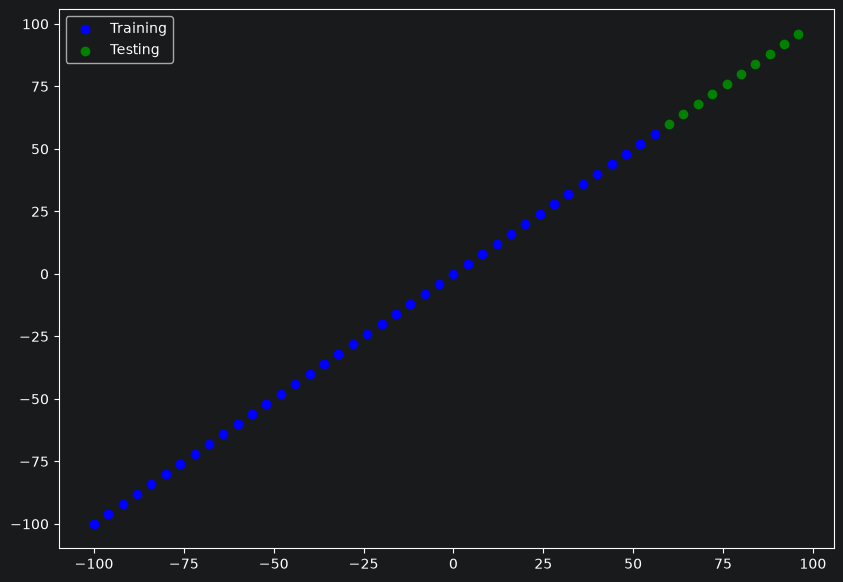

In [36]:
# visualiza con matplotlib los datos. Utiliza el color azul para los datos de training y el color verde para los datos de testing
plt.figure(figsize=(10, 7))
plt.scatter(X_train, y_train, c="b", label="Training")
plt.scatter(X_test, y_test, c="g", label="Testing")
plt.legend();

In [ ]:
# copia el modelo que hemos creado anteriormente y comenta la llamada a la función fit 

## Visualizando el modelo

Después de construir un modelo, es posible que quieras echarle un vistazo (especialmente si no has construido muchos antes).

Puedes ver las capas y las formas de tu modelo llamando a [`summary()`](https://www.tensorflow.org/api_docs/python/tf/keras/Model#summary) sobre él.

> 🔑 **Nota:** Visualizar un modelo es particularmente útil cuando te encuentras con desajustes en las formas de entrada y salida.


In [97]:
#Crear un modelo de una neurona, utilizar la funcion loss mae, optimizador sgd
tf.random.set_seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Dense(1, input_shape=[1], name="capa1"),
    tf.keras.layers.Dense(1),
],name="eje2_regresion")

model.compile(optimizer='sgd', loss='mae', metrics=['mae'])
# Invoca a la función summary
model.summary()


# No funciona del todo porque el modelo o nó está construido (build) o no está entrenado (fit)
# es decir, sabe el número de capas, pero no sabe el número de parámetros
# model.fit(tf.expand_dims(X_train, axis=-1), y_train, epochs=100)

Model: "eje2_regresion"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa1 (Dense)                   │ (None, 1)              │             2 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4 (16.00 B)

 Trainable params: 4 (16.00 B)

 Non-trainable params: 0 (0.00 B)

In [45]:
model.summary()

Model: "eje1_regresion"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa1 (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4 (20.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

Para que el modelo se imprima correctamente con todos los parámetros especificados, necesitamos añadir la forma de la entrada [1],
con esto keras puede calcular el número de parámetros de la red

In [54]:
from tensorflow.keras.utils import plot_model
plot_model(model, show_shapes=True)

ImportError: You must install pydot (`pip install pydot`) for `plot_model` to work.

In [ ]:
# si indicamos la forma de entrada a la capa 1, summary sí que es capaz de calcular los parámetros de la red 

como ves en el warning, no es la forma idónea, pero es un avance.

Llamar a `summary()` en nuestro modelo nos muestra las capas que contiene, la forma de salida y el número de parámetros.
* **Total params** - número total de parámetros en el modelo.
* **Parámetros entrenables** _(trainable params)_ - son los parámetros (patrones) que el modelo puede actualizar mientras se entrena.
* **Parámetros no entrenables** _(non-trainable params)_ - estos parámetros no se actualizan durante el entrenamiento (esto es típico cuando se utilizan patrones ya aprendidos de otros modelos durante el aprendizaje por transferencia).

> 📖 **Recurso:** Para una visión más profunda de los parámetros entrenables dentro de una capa, consulta el [video introductorio al aprendizaje profundo de MIT](https://youtu.be/njKP3FqW3Sk).

> 🛠 **Ejercicio:** Intenta experimentar con el número de unidades ocultas en la capa `Dense` (por ejemplo, `Dense(2)`, `Dense(3)`). ¿Cómo cambia esto los parámetros Totales/Entrenables? Investiga qué está causando el cambio.

Por ahora, todo lo que necesitas saber sobre estos parámetros es que representan patrones que el modelo puede aprender de los datos.

Vamos a entrenar nuestro modelo con los datos de entrenamiento.


In [98]:
# entrena ahora el modelo durante 50 épocas
model.fit(tf.expand_dims(X_train, axis=-1), y_train, epochs=1000)

Epoch 1/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 42.9517 - mae: 42.9517 
Epoch 2/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 42.7929 - mae: 42.7929 
Epoch 3/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 42.1807 - mae: 42.1807 
Epoch 4/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 39.7599 - mae: 39.7599
Epoch 5/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 30.1705 - mae: 30.1705
Epoch 6/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 8.3616 - mae: 8.3616 
Epoch 7/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 12.2515 - mae: 12.2515
Epoch 8/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 15.3628 - mae: 15.3628 
Epoch 9/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 17.8514 - mae: 17.8514
Epoch 10/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 22.1935 - mae: 22.1935 
Epoch 11/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 25.3789 - mae: 25.3789 
Epoch 12/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 9.1385 - mae: 9.1385 
Epoch 13/1000
2/2

In [66]:
# invoca a la función summary ¿Qué diferencia observas?
model.summary()

Model: "eje2_regresion"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa1 (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4 (20.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

#### Observa cómo la red ahora tiene 4 parámetros, 2 más que en el caso anterior. Estos son los parámetros del optimizador
Los **optimizer params** (parámetros del optimizador) son los valores configurables que controlan cómo un optimizador ajusta los pesos del modelo durante el entrenamiento. Estos incluyen parámetros como la **tasa de aprendizaje** (learning rate), que define el tamaño de los pasos que el optimizador da al actualizar los pesos, y otros como el **momento** (momentum), que ayuda a acelerar la convergencia. 


## Visualizando las predicciones

Ahora que tenemos un modelo entrenado, vamos a visualizar algunas predicciones.

Para visualizar predicciones, siempre es una buena idea graficarlas contra las etiquetas reales.

A menudo verás esto en la forma de `y_test` vs. `y_pred` (etiquetas reales vs. predicciones).

Primero, haremos algunas predicciones sobre los datos de prueba (`X_test`), recuerda que el modelo nunca ha visto los datos de prueba.


In [99]:
# realiza las predicciones sobre los datos de test
y_preds = model.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


Bien, obtenemos una lista de números, pero ¿cómo se comparan con las etiquetas reales?

Vamos a construir una función de plot para averiguarlo.


In [77]:
def plot_predictions(train_data, 
                     train_labels, 
                     test_data, 
                     test_labels, 
                     predictions):
  """
  Visualiza datos de entrenamiento y test y compara predicciones
  """
  plt.figure(figsize=(10, 7))
  # training en azul
  plt.scatter(train_data, train_labels, c="b", label="Training")
  # test en verde
  plt.scatter(test_data, test_labels, c="g", label="Testing")
  # predicciones en rojo
  plt.scatter(test_data, predictions, c="r", label="Predictions")
  
  plt.legend();

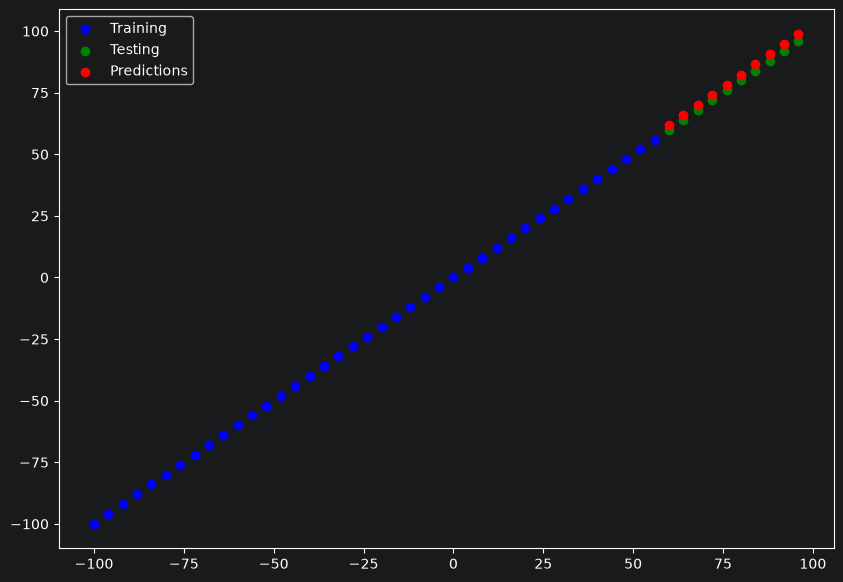

In [100]:
# usando la función anterior, visualiza los datos de prueba, de test y las predicciones
plot_predictions(X_train, y_train, X_test, y_test, y_preds)

#### ¿Cómo crees que resultó?
de la gráfica podemos ver que nuestras predicciones no son correctas, pero tampoco son desacertadas

## Evaluando las predicciones

Además de las visualizaciones, las métricas de evaluación son tu mejor opción alternativa para evaluar tu modelo.

Dependiendo del problema en el que estés trabajando, diferentes modelos tienen diferentes métricas de evaluación.

Dos de las principales métricas utilizadas para problemas de regresión son:
* **Error absoluto medio (MAE)** - la diferencia media entre cada una de las predicciones.
* **Error cuadrático medio (MSE)** - la diferencia media al cuadrado de las predicciones (se utiliza si los errores más grandes son más perjudiciales que los más pequeños).

Cuanto más bajos sean estos valores, mejor.

También puedes usar [`model.evaluate()`](https://www.tensorflow.org/api_docs/python/tf/keras/Model#evaluate), que devolverá la pérdida del modelo así como cualquier métrica configurada durante el paso de compilación.


In [101]:
# invoca al método evaluate pasando como parámetros X_test e y_test
model.evaluate(X_test, y_test)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 2.3224 - mae: 2.3224


[2.322436809539795, 2.322436809539795]

En nuestro caso, como usamos MAE como función de pérdida y también como métrica, `model.evaluate()` nos devuelve ambas.

TensorFlow también tiene funciones integradas para MSE y MAE.

Para muchas funciones de evaluación, el principio es el mismo: comparar las predicciones con las etiquetas reales.


In [104]:
# calcula el error absoluto medio con la función tf.keras.losses.MAE 
tf.keras.losses.MAE(y_test, tf.squeeze(y_preds))

<tf.Tensor: shape=(), dtype=float32, numpy=2.322436809539795>

¿Qué salida más rara, verdad? ¿No debería salir un único valor?
Esto es porque `y_test` y `y_preds` no tienen la misma forma (shape)


In [105]:
#examina la forma de y_test y y_preds
y_test.shape, y_preds.shape

((10,), (10, 1))

Podemos solucionarlo usando [`squeeze()`](https://www.tensorflow.org/api_docs/python/tf/squeeze), que eliminará la dimensión `1` de nuestro tensor `y_preds`, haciendo que tenga la misma forma que `y_test`.

> 🔑 **Nota:** Si estás comparando dos tensores, es importante asegurarse de que tengan las formas correctas (no siempre tendrás que manipular las formas, pero siempre presta atención, *muchos* errores son el resultado de tensores con formas incompatibles, especialmente en las formas de entrada y salida).


In [ ]:
# utiliza el método squeeze para eliminar la dimensión 1

In [ ]:
# prueba de nuevo la función MAE


In [ ]:
# calculas también el MSE


In [ ]:
# vamos a crear funciones para nuestras evaluaciones
def mae(y_test, y_pred):
  return tf.keras.losses.MAE(y_test, y_pred)
  
def mse(y_test, y_pred):
  return tf.keras.losses.MSE(y_test, y_pred)

## Ejecutando experimentos para mejorar un modelo

Después de ver las métricas de evaluación y las predicciones que hace tu modelo, es probable que quieras mejorarlo.

Nuevamente, hay muchas formas diferentes de hacerlo, pero 3 de las principales son:
1. **Obtener más datos** - conseguir más ejemplos para que tu modelo entrene (más oportunidades para aprender patrones).
2. **Hacer tu modelo más grande (usar un modelo más complejo)** - esto podría significar más capas o más unidades ocultas en cada capa.
3. **Entrenar por más tiempo** - darle a tu modelo más oportunidades de encontrar patrones en los datos.

Como creamos nuestro propio conjunto de datos, podríamos fácilmente generar más datos, pero esto no siempre es el caso cuando trabajas con conjuntos de datos del mundo real.

Así que vamos a ver cómo podemos mejorar nuestro modelo utilizando las opciones 2 y 3.

Para hacerlo, construiremos 3 modelos y compararemos sus resultados:
1. `model_1` - igual que el modelo original, 1 capa, entrenado durante 100 épocas.
2. `model_2` - 2 capas, entrenado durante 100 épocas.
3. `model_3` - 2 capas, entrenado durante 500 épocas.

*** vamos a construir `model_1`**


In [110]:
# crear model_1 y entrenalo durante 100 épocas
tf.random.set_seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Dense(1, input_shape=[1])
], name="model_1")

model.compile(optimizer='sgd', loss='mae', metrics=['mae'])
model.fit(tf.expand_dims(X_train, axis=-1), y_train, epochs=100)

Epoch 1/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 25.6405 - mae: 25.6405 
Epoch 2/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 7.4785 - mae: 7.4785 
Epoch 3/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 5.7409 - mae: 5.7409 
Epoch 4/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.0033 - mae: 4.0033 
Epoch 5/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 4.4608 - mae: 4.4608
Epoch 6/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 4.0032 - mae: 4.0032
Epoch 7/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.4609 - mae: 4.4609 
Epoch 8/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.0031 - mae: 4.0031 
Epoch 9/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.4610 - mae: 4.4610 
Epoch 10/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.0029 - mae: 4.0029 
Epoch 11/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 4.4611 - mae: 4.4611
Epoch 12/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.0028 - mae: 4.0028 
Epoch 13/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/s

In [112]:
# visualiza las predicciones
model.summary()

Model: "model_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_37 (Dense)                │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4 (20.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

Calculemos las métricas


In [122]:
model.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


array([[62.36984 ],
       [66.52785 ],
       [70.68586 ],
       [74.843864],
       [79.00188 ],
       [83.15989 ],
       [87.317894],
       [91.47591 ],
       [95.63392 ],
       [99.79192 ]], dtype=float32)

In [113]:
# visualiza la mae y la mse
print(tf.keras.losses.MAE(y_test, tf.squeeze(y_preds)))
print(tf.keras.losses.MSE(y_test, tf.squeeze(y_preds)))

tf.Tensor(2.3224368, shape=(), dtype=float32)
tf.Tensor(5.5155044, shape=(), dtype=float32)


**Modelo 2** (*model_2*) Esta vez agregaremos una capa densa adicional (así que ahora nuestro modelo tendrá 2 capas) manteniendo todo lo demás igual.


In [114]:
# crea ahora model_2, pero con una capa adicional de una unidad, entrénalo también durante 100 épocas
tf.random.set_seed(42)
model2 = tf.keras.Sequential([
    tf.keras.layers.Dense(1, input_shape=[1]),
    tf.keras.layers.Dense(1)
], name="model_2")

model2.compile(optimizer='sgd', loss='mae', metrics=['mae'])
model2.fit(tf.expand_dims(X_train, axis=-1), y_train, epochs=100)

Epoch 1/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 47.5190 - mae: 47.5190 
Epoch 2/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 21.7515 - mae: 21.7515 
Epoch 3/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 29.5533 - mae: 29.5533 
Epoch 4/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 6.1316 - mae: 6.1316 
Epoch 5/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 15.9537 - mae: 15.9537 
Epoch 6/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 18.3075 - mae: 18.3075 
Epoch 7/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 23.0784 - mae: 23.0784 
Epoch 8/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 23.2049 - mae: 23.2049
Epoch 9/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 9.9044 - mae: 9.9044
Epoch 10/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 13.4852 - mae: 13.4852 
Epoch 11/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 16.3496 - mae: 16.3496 
Epoch 12/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 19.0504 - mae: 19.0504 
Epoch 13/100
2/2 ━━━━━━━━━━━

In [115]:
# visualiza predicciones
model2.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


array([[58.956722],
       [62.888557],
       [66.8204  ],
       [70.752235],
       [74.68407 ],
       [78.615906],
       [82.54774 ],
       [86.479576],
       [90.411415],
       [94.34325 ]], dtype=float32)

.... raro.... hemos añadido una capa y el resultado es mucho peor, ¿quizá entrenando más épocas?

In [116]:
# muestra mae y mse
print(tf.keras.losses.MSE(y_test, tf.squeeze(y_preds)))
print(tf.keras.losses.MAE(y_test, tf.squeeze(y_preds)))

tf.Tensor(5.5155044, shape=(), dtype=float32)
tf.Tensor(2.3224368, shape=(), dtype=float32)


Construimos el **modelo 3** (_model_3_) que es igual, pero entrenando más épocas 

In [117]:
# construye el model_3 (Clon de model_2) y entrénalo 200 épocas
tf.random.set_seed(42)
model3 = tf.keras.Sequential([
    tf.keras.layers.Dense(1, input_shape=[1]),
    tf.keras.layers.Dense(1)
], name="model_3")
model3.compile(optimizer='sgd', loss='mae', metrics=['mae'])
model3.fit(tf.expand_dims(X_train, axis=-1), y_train, epochs=200)


Epoch 1/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 42.2868 - mae: 42.2868 
Epoch 2/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 13.5413 - mae: 13.5413 
Epoch 3/200
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 12.0316 - mae: 12.0316

/home/iabd/miniconda3/envs/rna/lib/python3.11/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 13.8405 - mae: 13.8405 
Epoch 4/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 16.4808 - mae: 16.4808 
Epoch 5/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 18.7068 - mae: 18.7068
Epoch 6/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 35.0401 - mae: 35.0401
Epoch 7/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 9.3907 - mae: 9.3907 
Epoch 8/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 14.7648 - mae: 14.7648 
Epoch 9/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 17.3695 - mae: 17.3695 
Epoch 10/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 21.1679 - mae: 21.1679 
Epoch 11/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 28.0289 - mae: 28.0289
Epoch 12/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 4.0684 - mae: 4.0684
Epoch 13/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 10.4239 - mae: 10.4239
Epoch 14/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 13.9014 - mae: 13.9014 
Epoch 15/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s

In [118]:
# realiza predicciones
model3.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


array([[25.147297],
       [26.827806],
       [28.508316],
       [30.188828],
       [31.869337],
       [33.549847],
       [35.23036 ],
       [36.91087 ],
       [38.591377],
       [40.271885]], dtype=float32)

In [119]:
# muestra mae y mse
print(tf.keras.losses.MSE(y_test, tf.squeeze(y_preds)))
print(tf.keras.losses.MAE(y_test, tf.squeeze(y_preds)))

tf.Tensor(5.5155044, shape=(), dtype=float32)
tf.Tensor(2.3224368, shape=(), dtype=float32)


In [ ]:
# crea un dataframe de pandas que aglutine los resultados de los experimentos

A partir de nuestros experimentos, parece que `model_3` fue el que mejor rendimiento tuvo.

Y ahora, probablemente estés pensando, "comparar modelos es un rollo..." y definitivamente puede serlo, aquí solo hemos comparado 3 modelos.

Pero esto es parte de lo que implica el modelado en machine learning: probar muchas combinaciones diferentes de modelos y ver cuál funciona mejor.

Cada modelo que construyes es un pequeño experimento.

> 🔑 **Nota:** Uno de tus principales objetivos debe ser minimizar el tiempo entre tus experimentos. Cuantos más experimentos realices, más cosas descubrirás que no funcionan y, a su vez, estarás más cerca de descubrir lo que sí funciona. Recuerda el lema del practicante de machine learning: "experimentar, experimentar, experimentar".

Otra cosa que también descubrirás es que lo que pensabas que funcionaría (como entrenar un modelo por más tiempo) puede no siempre funcionar, y a menudo ocurre lo contrario.

## Seguimiento de tus experimentos

Un muy buen hábito que puedes adoptar es hacer un seguimiento de tus experimentos de modelado para ver cuáles funcionan mejor que otros.

Hemos hecho una versión simple de esto arriba (guardando los resultados en diferentes variables).

> 📖 **Recurso:** Pero a medida que construyas más modelos, querrás considerar el uso de herramientas como:
* [**TensorBoard**](https://tensorboard.dev/) - un componente de la biblioteca TensorFlow para ayudar a hacer un seguimiento de los experimentos de modelado (veremos esto más adelante).
* [**Weights & Biases**](https://www.wandb.com/) - una herramienta para hacer seguimiento de todo tipo de experimentos de machine learning (la buena noticia es que Weights & Biases se integra con TensorBoard).

## Optimización automática de hiperparámetros:
* [**Optuna**](https://optuna.org/) - emplea estrategias de búsqueda como la optimización bayesiana para seleccionar automáticamente los hiperparámetros óptimos, lo que mejora el rendimiento de los modelos sin necesidad de probar manualmente múltiples combinaciones.

## Guardando un modelo

Una vez que has entrenado un modelo y encuentras uno que funciona a tu gusto, probablemente querrás guardarlo para usarlo en otro lugar (como una aplicación web o dispositivo móvil).

Puedes guardar un modelo de TensorFlow/Keras usando [`model.save()`](https://www.tensorflow.org/tutorials/keras/save_and_load#save_the_entire_model).

Hay dos formas de guardar un modelo en TensorFlow:
1. El formato Keras (nativo) [Keras](https://www.tensorflow.org/tutorials/keras/save_and_load#savedmodel_format) (por defecto).
2. El formato [HDF5](https://www.tensorflow.org/tutorials/keras/save_and_load#hdf5_format).

La principal diferencia entre los dos es que el formato SavedModel es capaz de guardar automáticamente objetos personalizados (como capas especiales) sin modificaciones adicionales al cargar el modelo de nuevo.

¿Cuál deberías usar?

Dependerá de tu situación, pero el formato SavedModel será suficiente la mayoría de las veces.

Ambos métodos utilizan la misma llamada de método.



In [123]:
# guarda el modelo 3 en formato keras
model3.save("miModelo3.keras")

In [ ]:
# guarda el modelo 3 en formato h5 (legacy)


Para cargar un modelo, tan sólo tenemos que usar la función load:


In [125]:
# carga el modelo y muestra su summary
miNuevoModelo = tf.keras.models.load_model("miModelo3.keras")

In [126]:
# utiliza el modelo cargado para realizar predicciones
miNuevoModelo.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


array([[25.147297],
       [26.827806],
       [28.508316],
       [30.188828],
       [31.869337],
       [33.549847],
       [35.23036 ],
       [36.91087 ],
       [38.591377],
       [40.271885]], dtype=float32)